<h1 align="center">Física Computacional.</h1>
<h1 align="center">Tarea Practica 4</h1>

<h2>Alumno: Monroy García Sebástian Dhamar </h2> 

---

### 1. Regla del Trapecio

El archivo `velocidades.txt` (adjunto), contiene dos columnas de números, la primera representa el tiempo $t$ en segundos y la segunda la $x$-velocidad en metros por segundo de una partícula, medida una vez por segundo desde el tiempo $t = 0$ hasta $t = 100$. Las primeras líneas se ven así:

```text
0 0
1 0.069478
2 0.137694
3 0.204332
4 0.269083
5 0.331656
```

Escribe un programa para hacer lo siguiente:

* **(a)** Lee los datos y, usando la **regla del trapecio**, calcula a partir de ellos la distancia aproximada recorrida por la partícula en la dirección $x$ como una función del tiempo.

In [10]:
import numpy as np
def metTrapecio(f,a,b,N):
    h=(b-a)/N
    I1=(f(a)+f(b))
    S1=0
    for i in range(1,int(N)):
        S1+=f(a+(i*h))
    return float(h*((I1/2)+S1))

In [11]:
tiempo=[]
velocidades=[]
txt = open("data/velocidades.txt","r")
for linea in txt:
    l=linea.split()
    tiempo.append(float(l[0]))
    velocidades.append(float(l[1]))

t=np.array(tiempo)
v=np.array(velocidades)

In [12]:
distancias=[0.0]

def v(x):
    return velocidades[int(round(x))]

for x in range(1, len(tiempo)):
    a=0
    b=x
    N=x
    x_t = metTrapecio(v, a, b, N)
    distancias.append(x_t)

distancias[-1]

8.21892400000002

---
* **(b)** Extiende tu programa para hacer una gráfica que muestre, en el mismo gráfico, tanto la curva de velocidad original como la distancia recorrida como una función del tiempo.

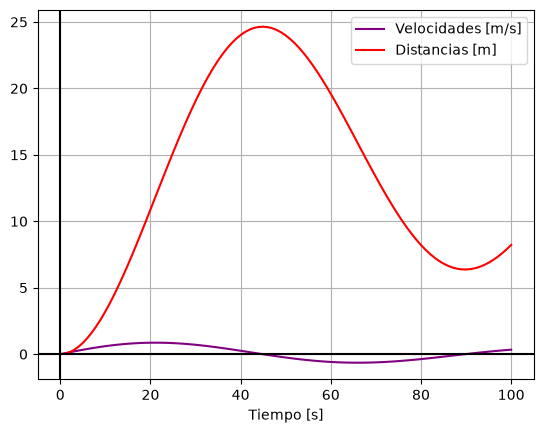

In [13]:
import matplotlib.pyplot as plt

tiempo=[]
velocidades=[]
txt = open("data/velocidades.txt","r")
for linea in txt:
    l=linea.split()
    tiempo.append(float(l[0]))
    velocidades.append(float(l[1]))
t=np.array(tiempo)
vel=np.array(velocidades)

distancias=[0.0]
def v(x):
    return velocidades[int(round(x))]
for x in range(1, len(tiempo)):
    a=0
    b=x
    N=x
    x_t = metTrapecio(v, a, b, N)
    distancias.append(x_t)
d=np.array(distancias)

plt.plot(t,vel, label="Velocidades [m/s]", color="purple")
plt.plot(t,d, label="Distancias [m]", color="red")
plt.xlabel("Tiempo [s]")
plt.axhline(y = 0.0, xmin = 0.0, color = 'black')
plt.axvline(x = 0.0, ymin = 0.0, color = 'black')
plt.legend()
plt.grid()
plt.show()


---
---
### 2. El límite de difracción de un telescopio.

Nuestra capacidad para resolver detalles en observaciones astronómicas está limitada por la difracción de la luz en nuestros telescopios. La luz de las estrellas puede considerarse efectivamente como si proviniera de una fuente puntual en el infinito. Cuando dicha luz, con una longitud de onda $\lambda$, pasa a través de la apertura circular de un telescopio (que supondremos que tiene un radio unitario) y es enfocada por el telescopio en el plano focal, no produce un solo punto, sino un patrón de difracción circular que consta de un punto central rodeado por una serie de anillos concéntricos. La intensidad de la luz en este patrón de difracción está dada por:

$$I(r) = \left( \frac{J_1(kr)}{kr} \right)^2,$$

donde $r$ es la distancia en el plano focal desde el centro del patrón de difracción, $k = 2\pi / \lambda$ y $J_1(x)$ es una función de Bessel. Las funciones de Bessel $J_m(x)$ están dadas por:

$$J_m(x) = \frac{1}{\pi} \int_0^\pi \cos(m\theta - x \sin(\theta)) \, \mathrm{d}\theta,$$

donde $m$ es un entero no negativo y $x \ge 0$.

---

**(a)** Escribe una función `J(m, x)` que calcule el valor de $J_m(x)$ usando la regla de Simpson con $N = 1000$ puntos. Utiliza dicha función en un programa para graficar, en un solo gráfico, las funciones de Bessel $J_0$, $J_1$ y $J_2$ como una función de $x$ (de $x = 0$ a $x = 20$).

In [55]:
import numpy as np
def IntegracionSimpson(f,a,b,N):
    h=(b-a)/N
    if N%2==0:
        I1=(f(a)+f(b))
        S1=0
        S2=0
        for i in range(1,int(N/2)+1):
            S1+=f(a+(((2*i)-1)*h))

        for i in range(1,(int(N/2))):
            S2+=f(a+(2*i*h))

        return float((h/3)*(I1+(4*S1)+(2*S2)))
    elif N%2!=0:
        return print("N debe ser par")

In [58]:
def J(m,x):
    def f(t):
        return np.cos((m*t)-(x*np.sin(t)))
    return (1/np.pi)*IntegracionSimpson(f,0,np.pi,1000)

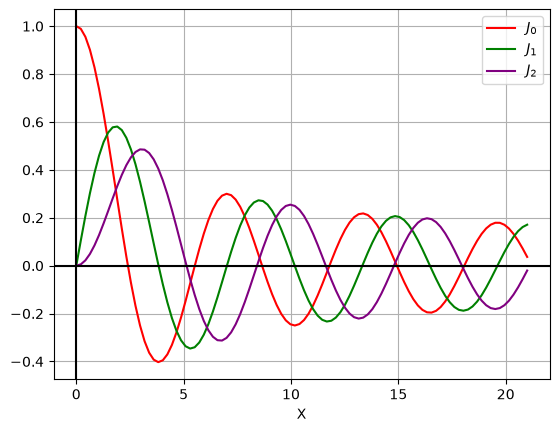

In [60]:
J0=[]
J1=[]
J2=[]
X=np.linspace(0,21,100)
for x in X:
    J0.append(J(0,x))
    J1.append(J(1,x))
    J2.append(J(2,x))
    
J0=np.array(J0)
J1=np.array(J1)
J2=np.array(J2)

plt.plot(X,J0, label="$J_0$", color="red")
plt.plot(X,J1, label="$J_1$", color="green")
plt.plot(X,J2, label="$J_2$", color="purple")
plt.xlabel("X")
plt.axhline(y = 0.0, xmin = 0.0, color = 'black')
plt.axvline(x = 0.0, ymin = 0.0, color = 'black')
plt.legend()
plt.grid()
plt.show()

---
**(b)** Compara tus resultados con los proporcionados con la biblioteca de `scipy` que implementa la regla de Simpson.

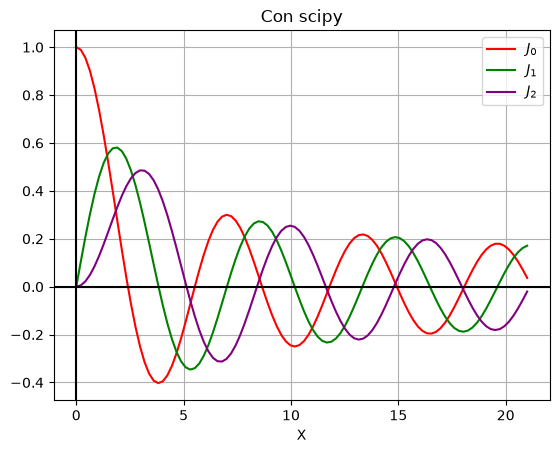

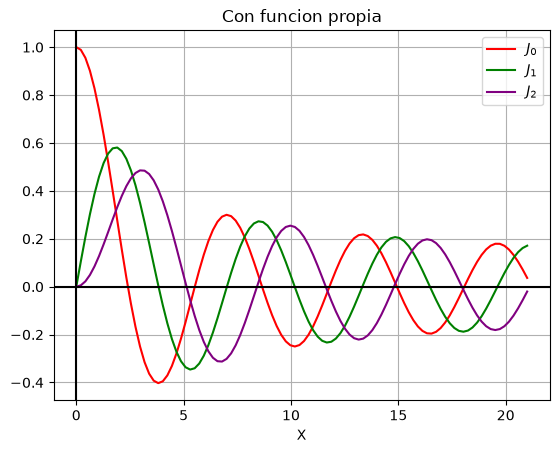

In [67]:
import scipy as sp
N=1000
X=np.linspace(0,21,100)

def Jsim(m,x):
    t=np.linspace(0,np.pi,N+1)
    y=np.cos((m*t)-(x*np.sin(t)))
    return (1/np.pi)*sp.integrate.simpson(y,t)

J0S=[]
J1S=[]
J2S=[]
for x in X:
    J0S.append(J(0,x))
    J1S.append(J(1,x))
    J2S.append(J(2,x))
    
J0S=np.array(J0S)
J1S=np.array(J1S)
J2S=np.array(J2S)

plt.plot(X,J0S, label="$J_0$", color="red")
plt.plot(X,J1S, label="$J_1$", color="green")
plt.plot(X,J2S, label="$J_2$", color="purple")
plt.xlabel("X")
plt.title("Con scipy")
plt.axhline(y = 0.0, xmin = 0.0, color = 'black')
plt.axvline(x = 0.0, ymin = 0.0, color = 'black')
plt.legend()
plt.grid()
plt.show()


plt.plot(X,J0, label="$J_0$", color="red")
plt.plot(X,J1, label="$J_1$", color="green")
plt.plot(X,J2, label="$J_2$", color="purple")
plt.xlabel("X")
plt.title("Con funcion propia")
plt.axhline(y = 0.0, xmin = 0.0, color = 'black')
plt.axvline(x = 0.0, ymin = 0.0, color = 'black')
plt.legend()
plt.grid()
plt.show()

In [72]:
D0=J0-J0S
D1=J1-J1S
D2=J2-J2S
print("La diferencia entre los metodos usados es, en J_0=",D0)
print("En J_1=",D1)
print("En J_3=",D2)

La diferencia entre los metodos usados es, en J_0= [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0.]
En J_1= [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0.]
En J_3= [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0.]


El resultado es el mismo

---
**(c)** Escribe un segundo programa que haga una gráfica de densidad (`density plot`) de la intensidad del patrón de difracción circular de una fuente de luz puntual con $\lambda = 500\text{ nm}$, en una región cuadrada del plano focal, usando la fórmula dada anteriormente. Su imagen debe cubrir valores de $r$ desde cero hasta aproximadamente $1\,\mu\text{m}$.

---

**Hint 1:** Puede resultarte útil saber que $\lim_{x \to 0} \frac{J_1(x)}{x} = \frac{1}{2}$.

**Hint 2:** El punto central en el patrón de difracción es tan brillante que puede resultar difícil ver los anillos que lo rodean en la pantalla de la computadora; para solucionar ésta situación puedes usar el esquema "hot" funciona bien. Tu gráfica debería verse algo así:
<div align="center">
    <img src="img/difraccion.png">
</div>

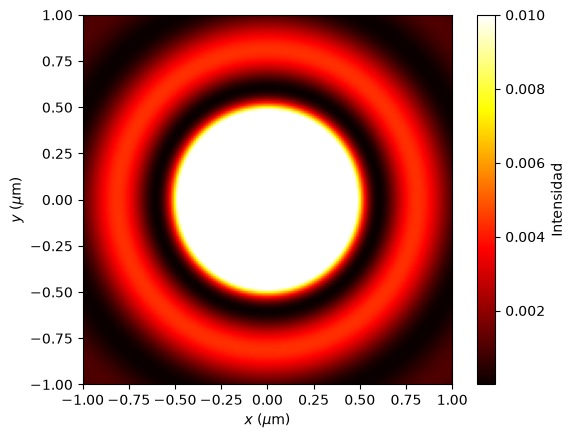

In [80]:
n=150
x=np.linspace(-(1*10**(-6))/2,(1*10**(-6))/2,n)
y=np.linspace(-(1*10**(-6))/2,(1*10**(-6))/2,n)
X,Y=np.meshgrid(x,y)
r=np.sqrt((X**2)+(Y**2))
Lambda=500*10**(-9)
k=(2*np.pi)/Lambda

def Ir(radio):
    kr=k*radio
    if kr==0:
        return 0.25
    else:
        return ((J(1,kr))/kr)**2

I=np.zeros_like(r)
for i in range(n):
    for j in range(n):
        I[i,j]=Ir(r[i,j])

plt.imshow(I,cmap="hot",extent=[-1, 1, -1, 1], vmax=0.01)
plt.colorbar(label="Intensidad")
plt.xlabel("$x$ ($\mu$m)")
plt.ylabel("$y$ ($\mu$m)")
plt.show()

---
---
### 3. Capacidad calorífica de un sólido

La *teoría de sólidos de Debye* dice que la *capacidad calorífica* de un sólido a una temperatura $T$ está dada por:

$$C_V = 9V \rho k_B \left( \frac{T}{\theta_D} \right)^3 \int_0^{\theta_D / T} \frac{x^4 e^x}{(e^x - 1)^2} \, \mathrm{d}x,$$

donde $V$ es el volumen del sólido, $\rho$ es la densidad numérica de los átomos, $k_B$ es la constante de Boltzmann y $\theta_D$ es la llamada *temperatura de Debye*, una propiedad de sólidos que depende de su densidad y la velocidad del sonido.

(a) Escribe una función `Cv(T)` que calcule la $C_V$ para un valor dado de temperatura, de una muestra que consta de $1000\text{ centímetros cúbicos}$ de aluminio sólido, con densidad numérica de $\rho = 6.022 \times 10^{28}\text{ m}^{-3}$ y una temperatura de Debye de $\theta_D = 428\text{ K}$. Utiliza la **cuadratura gaussiana** para evaluar la integral, con $N = 50$ puntos muestra.

In [88]:
def Cv(T):
    N=50
    V=1000*10**(-6)
    rho=6.022*10**28
    thetaD=428
    kB=1.380649*10**(-23)
    a=0
    b=thetaD/T    
    x_k,w_k=np.polynomial.legendre.leggauss(N)

    xk=((b-a)/2)*x_k +((b+a)/2)
    wk=((b-a)/2)*w_k
    
    def f(x):
        return ((x**4)*(np.exp(x)))/(((np.exp(x)-1)**2))
    S=0
    for i in range(len(xk)):
        S+=(wk[i])*f(xk[i])
    
    return float(9*V*rho*kB*((T/thetaD)**3)*S)

In [89]:
Cv(17)

12.180079731261856

---
(b) Usa tu función para hacer una gráfica de la capacidad calorífica en función de la temperatura desde $T = 5\text{ K}$ hasta $T = 500\text{ K}$.

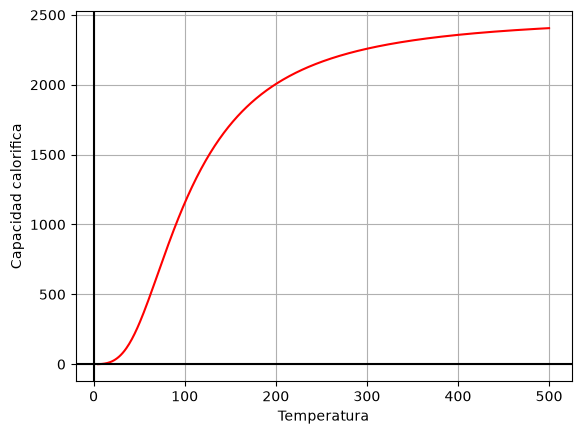

In [95]:
T=np.arange(5,501,1)
C=[]
for t in T:
    CV=Cv(t)
    C.append(CV)

plt.plot(T,C,color="red")
plt.xlabel("Temperatura")
plt.ylabel("Capacidad calorifica")
plt.axhline(y = 0.0, xmin = 0.0, color = 'black')
plt.axvline(x = 0.0, ymin = 0.0, color = 'black')
plt.grid()
plt.show()

---
---
### 4. Incertidumbre cuántica en el oscilador armónico.

En unidades donde todas las constantes son $1$, la función de onda del $n$-ésimo nivel de energía del oscilador armónico cuántico unidimensional, (i.e., una partícula puntual sin espín en un pozo de potencial cuadrático) está dada por:

$$\psi_n(x) = \frac{1}{\sqrt{2^n n! \sqrt{\pi}}} \mathrm{e}^{-x^2/2} H_n(x),$$

para $n = 0 \dots \infty$, donde $H_n(x)$ es el $n$-ésimo polinomio de Hermite. Los polinomios de Hermite satisfacen una relación algo similar a la de los números de Fibonacci, aunque más compleja:

$$H_{n+1}(x) = 2x H_n(x) - 2n H_{n-1}(x).$$

Los dos primeros polinomios de Hermite son $H_0(x) = 1$ y $H_1(x) = 2x$.

(a) Escribe una función `H(n,x)` que calcule $H_n(x)$ dados $x$ y cualquier número entero $n \ge 0$. Utiliza tu función para hacer una gráfica que muestre las funciones de onda del oscilador armónico para $n = 0, 1, 2$ y $3$, todos en el mismo gráfico, en el rango de $x = -4$ a $x = 4$. *Hint:* Hay una función `factorial` en el paquete `math` que calcula el factorial de un número entero.

In [120]:
import math as mt
def H(n,x):
    if n==0:
        return 1
    elif n==1:
        return 2*x
    elif n>=2:
        # return (2*x*H(n-1,x))-(2*(n-1)*H(n-2,x))
        h_2 = np.ones_like(x,dtype=float)
        h_1 = 2*x
        for i in range(1, n):
            h = 2.0 * x * h_1 - 2.0 * i * h_2
            h_2 = h_1
            h_1 = h
        return h

def psi(n,x):
    if n>=0:
        return (1/np.sqrt((2**n)*mt.factorial(n)*np.sqrt(np.pi)))*np.exp((-x**2)/2.0)*H(n,x)

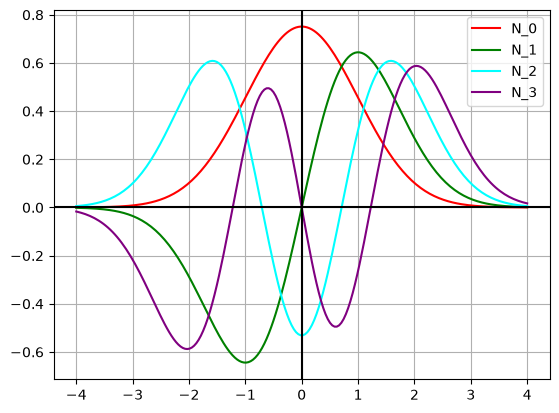

In [123]:
n=[0,1,2,3]
X=np.linspace(-4,4,200)

plt.plot(X,psi(0,X),label="N_0",color="red")
plt.plot(X,psi(1,X),label="N_1",color="green")
plt.plot(X,psi(2,X),label="N_2",color="cyan")
plt.plot(X,psi(3,X),label="N_3",color="purple")
plt.axhline(y = 0.0, xmin = 0.0, color = 'black')
plt.axvline(x = 0.0, ymin = 0.0, color = 'black')
plt.legend()
plt.grid()
plt.show()


---
(b) Haz una gráfica aparte, de la *función de onda* para $n = 30$ desde $x = -10$ hasta $x = 10$. *Hint:* si tu programa tarda demasiado en ejecutarse en este caso, entonces está haciendo mal el cálculo; el programa debería tardar aproximadamente un segundo en ejecutarse.

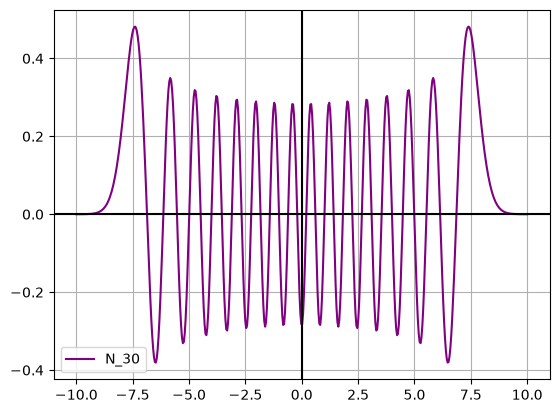

In [125]:
n=30
X=np.linspace(-10,10,500)

plt.plot(X,psi(n,X),label="N_30",color="purple")
plt.axhline(y = 0.0, xmin = 0.0, color = 'black')
plt.axvline(x = 0.0, ymin = 0.0, color = 'black')
plt.legend()
plt.grid()
plt.show()


---
(c) La incertidumbre cuántica de una partícula en el $n$-ésimo nivel de un oscilador armónico cuántico se puede cuantificar mediante su *media cuadrática* $\sqrt{\langle x^2 \rangle}$, donde:

$$\langle x^2 \rangle = \int_{-\infty}^{\infty} x^2 \vert{}\psi_n(x)\vert{}^2 \, \mathrm{d}x.$$

Escribe un programa que evalúe esta integral usando la cuadratura gaussiana en 100 puntos y luego calcula la incertidumbre (es decir, la posición media cuadrática de la partícula) para un valor dado de $n$. Utiliza tu programa para calcular la incertidumbre para $n = 5$. Deberías obtener una respuesta cercana a $\sqrt{\langle x^2 \rangle} = 2.3$.

In [159]:
def mecu(n):
    N=100
    a=-10
    b=10
    # los limites a $\pm$10 pues la exponencial en psi hace que sean suficientemente grandes como para considerarlo una aproximacion a infinito.
    x_k,w_k=np.polynomial.legendre.leggauss(N)
    xk=((b-a)/2)*x_k +((b+a)/2)
    wk=((b-a)/2)*w_k
    
    def f(n,x_k):
        return (x_k**2)*((psi(n,x_k))**2)
    S=0
    for i in range(len(xk)):
        S+=(wk[i])*f(n,xk[i])
    
    return float(np.sqrt(S))

In [160]:
mecu(5)

2.3452078799117144

---
---
### 5. Atracción gravitacional de una lámina uniforme

Una lámina de metal cuadrada uniforme flota inmóvil en el espacio:

<div align="center">
    <img src="img/atgrav.png">
</div>

La lámina mide $10\text{ m}$ de lado, tiene un espesor insignificante y una masa de $10\text{ toneladas}$.

---
(a) Considera la fuerza gravitacional debida a la placa que siente una masa puntual de $1\text{ kg}$ a una distancia $z$ del centro del cuadrado, en dirección perpendicular a la lámina, como se muestra en la figura. Demuestra que la componente de la fuerza a lo largo del eje $z$ es

$$F_z = G\sigma z \iint_{-L/2}^{L/2} \frac{\mathrm{d}x\,\mathrm{d}y}{(x^2 + y^2 + z^2)^{3/2}},$$

donde $G = 6.674 \times 10^{-11}\text{ m}^3\,\text{kg}^{-1}\,\text{s}^{-2}$ es la constante gravitacional de Newton y $\sigma$ es la masa por unidad de área de la hoja.

---
Partiendo de que:

$$dF=\frac{Gm_0dm}{r^2}û_r \longrightarrow dF_z=dF\cdot \frac{z}{r}=\frac{Gm_0zdm}{r^3}$$

Con la masa de prueba $m_0=1kg$, la distancia $r=\sqrt(x^2+y^2+z^2)$ y la diferencial de masa $dm=\sigma dA=\sigma dxdy$, entonces:

$$dF_z=\frac{Gz\sigma dxdy}{(x^2+y^2+z^2)^{3/2}}$$

Integrando respecto a dx y dy en una lamina cuadrada de lados L, nuestros limites, en ambos integraciones, son de -L/2 a L/2:

$$F_z=\int^{L/2}_{-L/2}\int^{L/2}_{-L/2}\frac{Gz\sigma dxdy}{(x^2+y^2+z^2)^{3/2}}$$

Como G, $\sigma$ y z son constantes respecto la integracion en x e y, salen de forma que se llega a:

$$F_z=Gz\sigma\int^{L/2}_{-L/2}\int^{L/2}_{-L/2}\frac{dxdy}{(x^2+y^2+z^2)^{3/2}}$$

Siendo esta la expresion a la que buscabamos llegar.

---
(b) Escribe un programa para calcular y graficar la fuerza en función de $z$ desde $z = 0$ hasta $z = 10\text{ m}$. Para la integral doble utiliza la cuadratura Gaussiana (doble)

$$I \simeq \sum_{i=1}^N \sum_{j=1}^N \omega_i \omega_j f(x_i, x_j),$$

con 100 puntos de muestra a lo largo de cada eje.

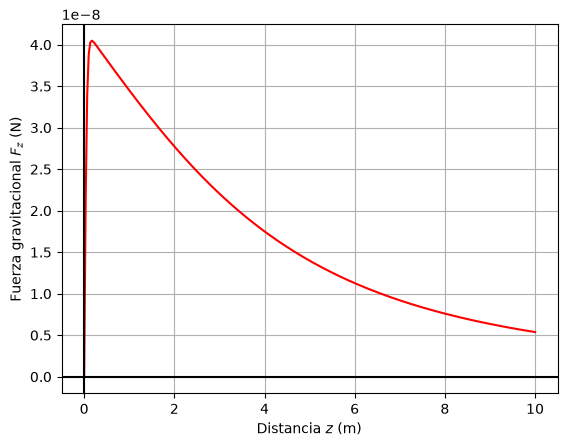

In [186]:
L = 10
M = 10000
sigma = M / (L**2) 
G = 6.674*10**(-11)
N = 100
a= -L/2
b = L/2
x_k, w_k = np.polynomial.legendre.leggauss(N)
xk = ((b-a)/2)*x_k+((b+a)/2)
wk = ((b-a)/2)*w_k

X, Y = np.meshgrid(xk, xk)
Wx,Wy = np.meshgrid(wk, wk)
W= Wx*Wy


def grav(z):
    if z == 0:
        return 0
    f= 1/((X**2 + Y**2 + z**2)**(3/2))
    S = np.sum(W * f)
    return G*sigma*z*S


Z = np.linspace(0, 10, 300)
F=[]
for z in Z:
    za=grav(z)
    F.append(za)

plt.plot(Z, F, color='red')
plt.xlabel('Distancia $z$ (m)')
plt.ylabel('Fuerza gravitacional $F_z$ (N)')
plt.axhline(y = 0.0, xmin = 0.0, color = 'black')
plt.axvline(x = 0.0, ymin = 0.0, color = 'black')
plt.grid()
plt.show()

---
(c) Deberías ver una curva suave, excepto en valores muy pequeños de $z$, donde la fuerza debería caer repentinamente a cero. Esta caída no es un efecto real, sino un artefacto de la forma en que hemos realizado el cálculo. Explica brevemente de dónde viene este artefacto y sugiere una estrategia para eliminarlo, o al menos disminuir su tamaño.

Este cálculo puede considerarse como un modelo de la atracción gravitacional de una galaxia. La mayor parte de la masa de una galaxia espiral (como nuestra Vía Láctea) se encuentra en un plano o disco delgado que pasa por el centro galáctico, y la atracción gravitacional ejercida por ese plano sobre cuerpos fuera de la galaxia se puede calcular con los métodos que hemos empleado aquí.

---
Esta caida proviene de la parte:
$$\frac{z}{(x^2+y^2+z^2)^{3/2}}$$

Cuando $z\rightarrow 0$, el resultado tiende a 0 en casi toda la superficie del plano, lugares donde $x^2+y^2>0$, pero en el origen (0,0,0), la funcion tiende a infinito, en el caso de este codigo, los puntos $x_i$ y $y_i$ nunca caen exactamente el (0,0) pues se toman los valores $x_k$ en el intervalo [-1,1] con 100 puntos discretos, y al ser 100 un numero par, el medio entre ambos valores, es decir 0, no es uno de los valores tomados. Y al hacer el escalamiento posterior tampoco se toma este valor pues deberia exitir el origen inicialmente para que fuese asi.

Entonces, conforme $z\rightarrow 0$, aunque en teoria la integracion se deberia acercar a un pico muy alto, como z es mas pequeña que la separacion entre los puntos discretos $x_i$ y $y_i$, la funcion solamente colapsa tendiendo a 0.

Para resolverlo o disminuir su efecto, se puede incrementar los puntos, siendo los que influirian aquellos cerca del origen cuando $z$ sea pequeño, al la separacien de los puntos $x_i$ y $y_i$ ser menor, el colapso ocurriria en una region mas pequeña, tambien si se hace un cambio a coordenadas polares, el diferencial de área añade un factor $r$ que suaviza matemáticamente la singularidad en el centro y permitiria evaluar de mejor forma antes de colapsar. 

---
---
## 6. Rejillas de difracción

La luz con longitud de onda $\lambda$ incide sobre una rejilla de difracción de ancho total $w$, se difracta, se enfoca con una lente convergente de distancia focal $f$ y proyecta sobre una pantalla:

<div align="center">
    <img src="img/rej.png">
</div>

La teoría nos dice que la intensidad del patrón de difracción en la pantalla, a una distancia $x$ del eje central del sistema, está dada por

$$I(x) = \left\vert{} \int_{-w/2}^{w/2} \sqrt{q(u)} \, \mathrm{e}^{\mathrm{i} 2\pi x u / \lambda f} \, \mathrm{d}u \right\vert{} \space ^2,$$

donde $q(u)$ es la función de transmisión de intensidad de la rejilla de difracción a una distancia $u$ del eje central, i.e., la fracción de la luz incidente que deja pasar la rejilla.

---

**(a)** Considera una rejilla con función de transmisión $q(u) = \sin^2 \alpha u$. ¿Cuál es la separación de las "rendijas" en esta rejilla, expresada en términos de $\alpha$?

Partiendo de que:
$$q(u)=sin^2(\alpha u)$$
y de la expresion del seno cuadrado:
$$sin^2\theta = \frac{1-cos(2\theta)}{2} \longrightarrow q(u)=\frac{1-cos(2\alpha u)}{2}$$
Ahora, las rendijas se ubican en las regiones donde la transmision es maxima, es decir, $q(u)=1$:
$$1=\frac{1-cos(2\alpha u)}{2} \longrightarrow 2=1-cos(2\alpha u) \longrightarrow cos(2\alpha u)=-1$$
Y esto pasa cuando $2\alpha u=(2n+1)\pi$, con lo que podemos llegar a que:
$$u_n=\frac{(2n+1)\pi}{2\alpha}$$
Con esto podemos hallar la separacion entre 2 rendijas consecutivas $u_n$ y $u_{n+1}$
$$d=u_{n+1}-u_n=\frac{(2(n+1)+1)\pi}{2\alpha}-\frac{(2n+1)\pi}{2\alpha}=\frac{2n\pi+3\pi-2n\pi-\pi}{2\alpha}=\frac{2\pi}{2\alpha}$$
Por lo tanto la separacion de las rendijas es:
$$d=\frac{\pi}{\alpha}$$

---
**(b)** Escribe una función en Python `q(u)` que devuelva la transmisión (i.e. $q(u) = \sin^2 \alpha u$) para una rejilla cuyas rendijas tienen una separación $20\ \mu\text{m}$.

In [6]:
d=20*10**(-6)
al= np.pi/d

def q(u):
    return np.sin(al*u)**2

---
**(c)** Utiliza tu función en un programa para calcular y representar gráficamente la intensidad del patrón de difracción producido por dicha rejilla con diez rendijas en total, si la luz incidente tiene una longitud de onda $\lambda = 500\text{ nm}$. Supongamos que la lente tiene una distancia focal de $1\text{ metro}$ y la pantalla tiene $10\text{ cm}$ de ancho. Puedes utilizar cualquier método que creas apropiado para hacer la integral. Una vez que hayas hecho tu elección, también deberás decidir la cantidad de puntos de muestra que utilizarás. ¿Qué criterios influyen en esta decisión?

Observa que el integrando en la ecuación para $I(x)$ es un valor complejo, por lo que tendrás que usar variables complejas en tu programa.

In [7]:
import numpy as np
def IntegracionSimpson2(f,a,b,N):
    h=(b-a)/N
    if N%2==0:
        I1=(f(a)+f(b))
        S1=0
        S2=0
        for i in range(1,int(N/2)+1):
            S1+=f(a+(((2*i)-1)*h))

        for i in range(1,(int(N/2))):
            S2+=f(a+(2*i*h))

        return (h/3)*(I1+(4*S1)+(2*S2))
    elif N%2!=0:
        return print("N debe ser par")

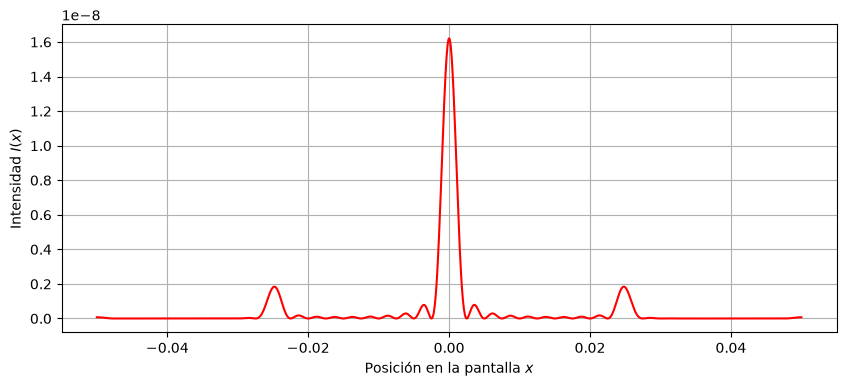

In [14]:
d=20*10**(-6)
al= np.pi/d
lamb=500*10**(-9)
f=1
w=10*d
dx=0.1
Nx=1500
n=1000

X=np.linspace(-dx/2,dx/2,Nx)
I=[]

def fx(u,x):
    return np.sqrt(q(u))*np.exp((1j*2*np.pi*x*u)/(lamb*f))

for i, xi in enumerate(X):
    def fu(u):
        return fx(u, xi)
    I1 = IntegracionSimpson2(fu,-w/2,w/2,n)
    I2=np.abs(I1)**2
    I.append(I2)
    
plt.figure(figsize=(10, 4))
plt.plot(X, I,"r")
plt.xlabel("Posición en la pantalla $x$")
plt.ylabel("Intensidad $I(x)$")
plt.grid()
plt.show()

---
**(d)** Crea una visualización de cómo se vería el patrón de difracción en la pantalla usando un gráfico de densidad. Tu gráfico debería verse así:

<div align="center">
    <img src="img/espectro.png">
</div>

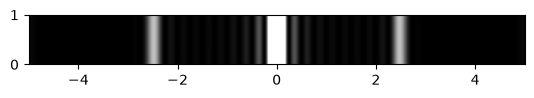

In [17]:
Ia=np.array(I)
na=200
Ia2=np.tile(Ia,(na,1))
plt.imshow(Ia2,extent=[-dx / 2 * 100, dx / 2 * 100, 0, 1],vmax=0.15 * np.max(Ia))
#Sin el vmax se ven bien la linea central y las de los costados, pero las intermedias no se distinguen mucho.
plt.gray()

---
**(e)** Modifica aún más su programa para crear imágenes de los patrones de difracción producidos por rejillas con los siguientes perfiles:

1. Un perfil de transmisión que obedece a $q(u) = \sin^2 \alpha u \, \sin^2 \beta u$.  
   Con $\alpha$ y $w$ (ancho total de rejilla) igual que antes; y $\beta = \frac{1}{2}\alpha$.

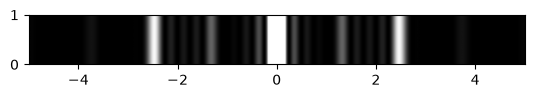

In [238]:
d=20*10**(-6)
al= np.pi/d
be= al/2
def q1(u):
    return (np.sin(al*u)**2)*(np.sin(be*u)**2)
lamb=500*10**(-9)
f=1
w=10*d
dx=0.1
Nx=1500
n=1000
X1=np.linspace(-dx/2,dx/2,Nx)
I_1=[]
def fx(u,x):
    return np.sqrt(q1(u))*np.exp((1j*2*np.pi*x*u)/(lamb*f))
for i, xi in enumerate(X1):
    def fu(u):
        return fx(u, xi)
    I_1a = IntegracionSimpson2(fu,-w/2,w/2,n)
    I_2a=np.abs(I_1a)**2
    I_1.append(I_2a)
Ia_1=np.array(I_1)
na=200
Ia2_1=np.tile(Ia_1,(na,1))
plt.imshow(Ia2_1,extent=[-dx / 2 * 100, dx / 2 * 100, 0, 1],vmax=0.15 * np.max(Ia_1))
plt.gray()



2. Dos rendijas "cuadradas", es decir, rendijas con $100\%$ de transmisión a través de la rendija y $0\%$ de transmisión en cualquier otro lugar. Calcule el patrón de difracción para rendijas no idénticas, una de $10\ \mu\text{m}$ de ancho y la otra de $20\ \mu\text{m}$ de ancho, con un espacio de $60\ \mu\text{m}$ entre las dos.

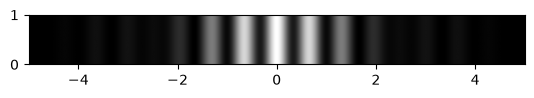

In [244]:
d2=60*10**(-6)
w1=10*10**(-6)
w2=20*10**(-6)
def q2(u):
    if (-d2/2 - w1) <= u <= -d2/2:
        return 1
    elif d2/2<= u <= (d2/2 + w2):
        return 1
    else:
        return 0
lamb=500*10**(-9)
f=1
lim=60*10**(-6)
dx=0.1
Nx=1500
n=1000
X2=np.linspace(-dx/2,dx/2,Nx)
I_2=[]
def fx(u,x):
    return np.sqrt(q2(u))*np.exp((1j*2*np.pi*x*u)/(lamb*f))
for i, xi in enumerate(X2):
    def fu(u):
        return fx(u, xi)
    I_1b = IntegracionSimpson2(fu,-lim,lim,n)
    I_2b=np.abs(I_1b)**2
    I_2.append(I_2b)
Ia_2=np.array(I_2)
na=200
Ia2_2=np.tile(Ia_2,(na,1))
plt.imshow(Ia2_2,extent=[-dx / 2 * 100, dx / 2 * 100, 0, 1])
plt.gray()
